In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats.contingency import association
import seaborn as sns
from joblib import dump
import os
import sys
from pathlib import Path

# Configure base directory for both Google Colab and local environments
if "google.colab" in sys.modules:
    drive_path = Path("/content/drive/MyDrive/pytorch-projects/pytorch-tabular-binary-classifier")
    if not drive_path.exists():
        from google.colab import drive
        drive.mount("/content/drive")

    if drive_path.exists():
        base = str(drive_path)
    else:
        repo_name = "pytorch-tabular-binary-classifier"
        if not Path(repo_name).exists():
            !git clone https://github.com/nfor-ojong/pytorch-tabular-binary-classifier.git
        base = repo_name
else:
    cwd = Path.cwd()
    base = str(cwd.parent if cwd.name == "notebooks" else cwd)

os.makedirs(f"{base}/artifacts", exist_ok=True)
os.makedirs(f"{base}/data/cleaned-data", exist_ok=True)
os.makedirs(f"{base}/evaluation-metrics", exist_ok=True)
os.makedirs(f"{base}/model", exist_ok=True)
os.makedirs(f"{base}/plots", exist_ok=True)

Mounted at /content/drive


In [2]:
# Determine Cramer's V correlation between nominal variables
def nominal_corr(df, cat_cols):

  # Contingency tables and Cramer's V correlation

  # Initialize empty matrix for Cramer's V values
  cramers_v_matrix = pd.DataFrame(
      np.eye(len(cat_cols)), # identity matrix
      index = cat_cols,
      columns = cat_cols
  )

  for i in range(len(cat_cols)):
    for j in range(i, len(cat_cols)):
      if i ==j:
        continue # do nothing since since correlation is 1 and np.eye() already produced an indentity matrix
      col1, col2 = cat_cols[i], cat_cols[j]
      ct = pd.crosstab(df[col1], df[col2]) # shows the frequency of every cross pair between the two columns

      # Guard against single-category columns (prevent ValueError)
      if ct.shape[0] > 1 and ct.shape[1] > 1:
        v = association(ct, method="cramer")
      else:
        v = 0.0
      cramers_v_matrix.iloc[i, j] = v
      cramers_v_matrix.iloc[j, i] = v

  return cramers_v_matrix.round(4) # round results to 4 decimal places

# Remove outliers from continuous variables
def outlier_fences(df, col):
  """
  > Computes statistical lower and upper fences for each continuous variable in dataset
  > Returns lower and upper fences
  > Will be applied on training set to get the fences, and those fences will be applied on the test and
    validation sets
  """

  # Quantile calculation ignores missing values by default
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  # Calculate lower and upper fences
  lower = Q1 - 1.5*IQR
  upper = Q3 + 1.5*IQR

  return lower, upper # return lower and upper fences

In [3]:
df = pd.read_csv(base + "/data/raw-data/framingham.csv") # load dataset

In [4]:
df.head() # first few samples of dataset

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [5]:
df.info() # get dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [6]:
df.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [7]:
100 * df.isna().sum() / df.shape[0] # check percentage of missing values per column

,0
male,0.000000
age,0.000000
education,2.477584
currentSmoker,0.000000
cigsPerDay,0.684285
BPMeds,1.250590
prevalentStroke,0.000000
prevalentHyp,0.000000
diabetes,0.000000
totChol,1.179802


In [8]:
# Separate numerical and categorical features
num_cols = []
cat_cols = []
for column in df.columns:
  if 2 <= len(set(df[column].dropna())) <= 10:
    cat_cols.append(column)
  else:
    num_cols.append(column)

In [9]:
cat_cols # categorical variables in dataset

['male',
 'education',
 'currentSmoker',
 'BPMeds',
 'prevalentStroke',
 'prevalentHyp',
 'diabetes',
 'TenYearCHD']

In [10]:
num_cols # numerical variables in dataset

['age',
 'cigsPerDay',
 'totChol',
 'sysBP',
 'diaBP',
 'BMI',
 'heartRate',
 'glucose']

In [11]:
len(cat_cols + num_cols) == len(df.columns) # Check that there are no columns with only one value

True

TenYearCHD
0    84.804153
1    15.195847
Name: count, dtype: float64


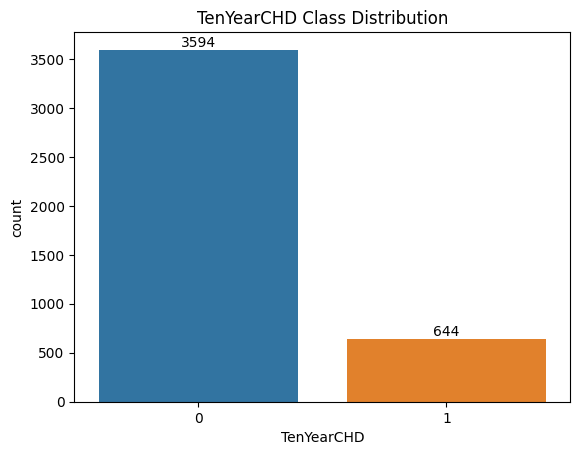

In [12]:
print(100*df["TenYearCHD"].value_counts() / df.shape[0]) # percentage of each class in target

# Count plot of TenYearCHD
ax = sns.countplot(data=df, x="TenYearCHD", hue="TenYearCHD", legend=False) # counts the number of observations of each class and plots
for container in ax.containers:
  ax.bar_label(container) # include the number of observations of each class at the top of each bar

plt.title("TenYearCHD Class Distribution")
plt.savefig(base + "/plots/target_class_distribution.png")
plt.show()

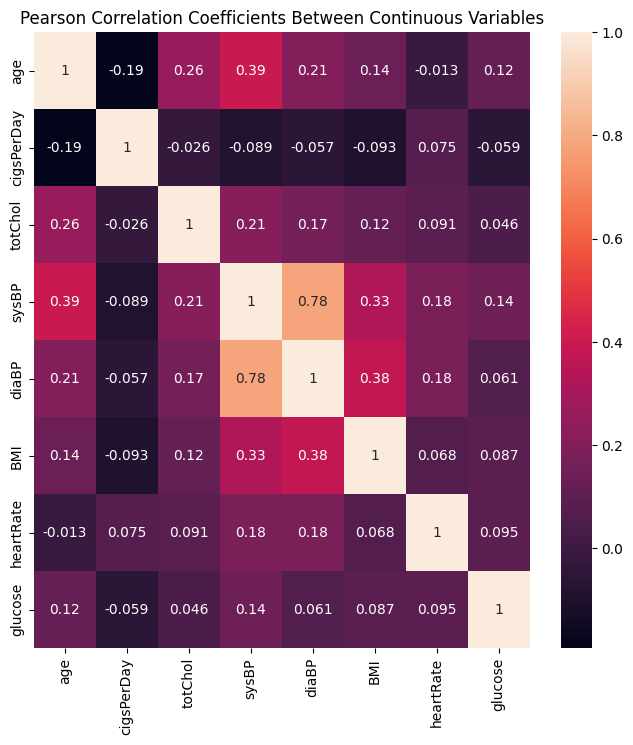

In [13]:
# Calculate and visualize Pearson's correlation coefficient for continuous variables
corr_pearson = df[num_cols].corr(method="pearson")

plt.figure(figsize=(8, 8))
sns.heatmap(corr_pearson, annot=True)
plt.title("Pearson Correlation Coefficients Between Continuous Variables")
plt.show()

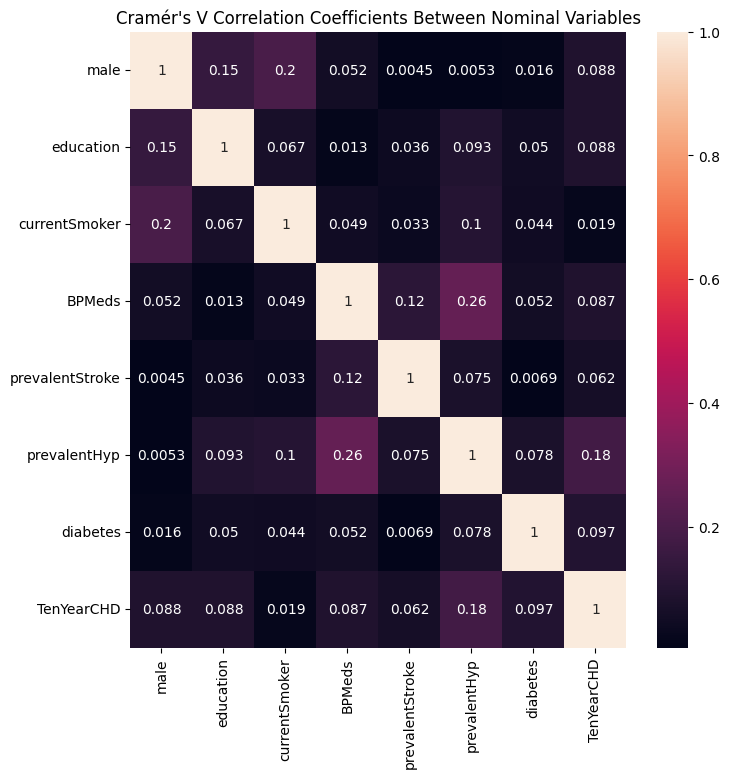

In [14]:
# Calculate and visualize Chi-square correlation for nominal variables
corr_cs = nominal_corr(df, cat_cols)
plt.figure(figsize=(8, 8))
sns.heatmap(corr_cs, annot=True)
plt.title("Cramér's V Correlation Coefficients Between Nominal Variables")
plt.show()

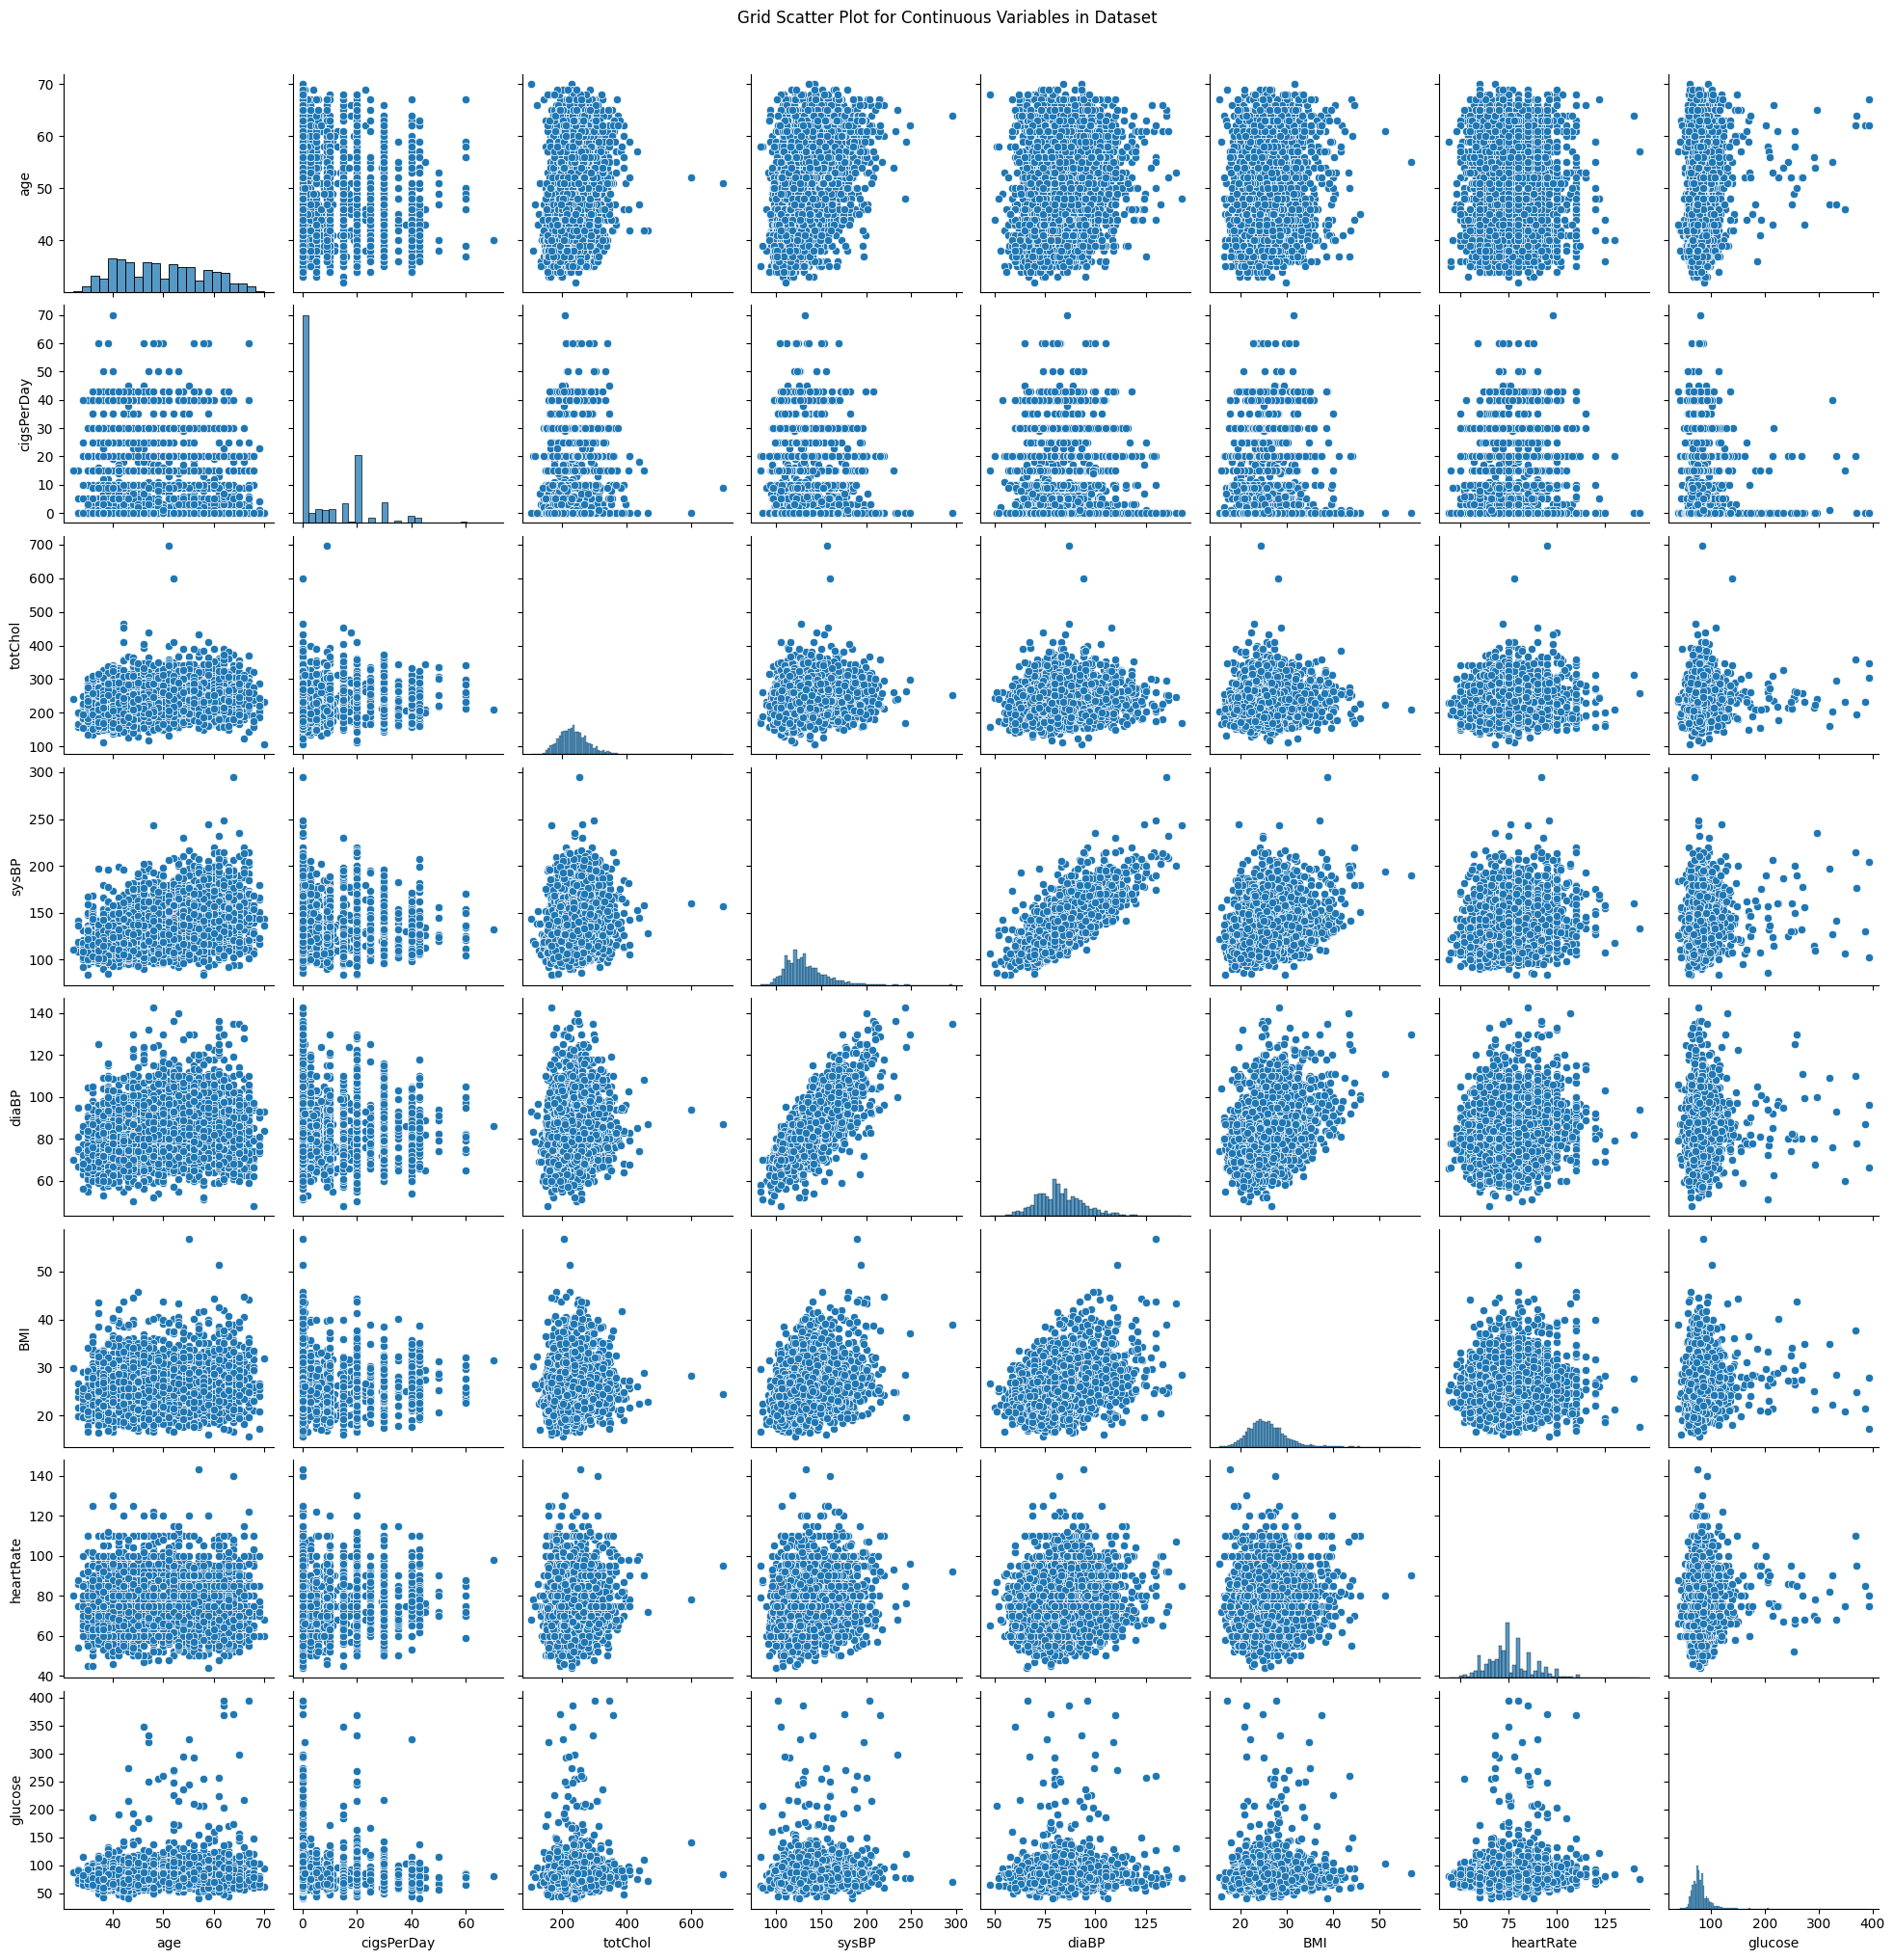

In [15]:
# Pairplot for Continuous variables
g = sns.pairplot(data=df[num_cols])
g.fig.suptitle("Grid Scatter Plot for Continuous Variables in Dataset", y=1.02)# place title 2% above the top edge
plt.show()

In [16]:
# Split data into training, validation, and testing sets while forcing each split to keep the same class percentages
# as the original dataset

target = "TenYearCHD"
features = list(df.columns)
features.remove(target)

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # create split with the same proportion of target as in y
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

# Display shapes of data frames
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_val shape: ", X_val.shape)
print("y_val shape: ", y_val.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (2542, 15)
y_train shape:  (2542,)
X_val shape:  (848, 15)
y_val shape:  (848,)
X_test shape:  (848, 15)
y_test shape:  (848,)


In [17]:
# Handle Outliers
# Compute lower and upper fences from training set
lower_train, upper_train = outlier_fences(X_train, num_cols)

# Handle outliers in training set
X_train[num_cols] = X_train[num_cols].clip(lower_train, upper_train, axis=1)

# Handle outliers in validation set using the same fences cumputed from the training set
X_val[num_cols] = X_val[num_cols].clip(lower_train, upper_train, axis=1)

# Handle outliers in test set using the same fences computed from the training set
X_test[num_cols] = X_test[num_cols].clip(lower_train, upper_train, axis=1)

In [18]:
# Handle missing values in training, validation, and testing sets
# Scale features to the same range

cat_cols.remove(target) if target in cat_cols else None # remove target from categorical columns list if its in there, else do nothing

num_imputer = SimpleImputer(strategy="median") # numerical columns imputer
cat_imputer = SimpleImputer(strategy = "most_frequent") # categorical columns imputer

scaler = StandardScaler() # scaler

# Fit imputer on training set and scale
X_train[num_cols] = scaler.fit_transform(num_imputer.fit_transform(X_train[num_cols]))
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])

# Transform validation set: impute and scale
X_val[num_cols] = scaler.transform(num_imputer.transform(X_val[num_cols]))
X_val[cat_cols] = cat_imputer.transform(X_val[cat_cols])

# Transform test set : impute and scale
X_test[num_cols] = scaler.transform(num_imputer.transform(X_test[num_cols]))
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

In [19]:
# One-Hot-Encode Education
"""
We perform One-Hot-Encoding on Education (ordinal with values 1, 2, 3, 4) so that the Neural Network/Linear model
does not think that the jump in cardiovascular risk between two consecutive education levels in identical.
"""

col_to_encode = ["education"]
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore") # spare_output = False returns a pandas data frame
# and not a numpy array. handle_unknown="igonore" prevents errors if val/test cotains unseen class(es)
train_encoded = encoder.fit_transform(X_train[col_to_encode])
val_encoded = encoder.transform(X_val[col_to_encode])
test_encoded = encoder.transform(X_test[col_to_encode])

# Get clean column names. e.g. 'education_1.0', 'education_2.0', ...
encoded_cols = encoder.get_feature_names_out(col_to_encode)

# Combine the data
X_train = pd.concat([
    X_train.drop(columns=col_to_encode),
    pd.DataFrame(train_encoded, columns=encoded_cols, index=X_train.index)
], axis=1)

X_val = pd.concat([
    X_val.drop(columns=col_to_encode),
    pd.DataFrame(val_encoded, columns=encoded_cols, index=X_val.index)
], axis=1)

X_test = pd.concat([
    X_test.drop(columns=col_to_encode),
    pd.DataFrame(test_encoded, columns=encoded_cols, index=X_test.index)
], axis=1)

In [20]:
# Save training, validation, and test data frames

# Combine training data
train_processed = X_train.copy()
train_processed["TenYearCHD"] = y_train.copy()

# Combine validation data
val_processed = X_val.copy()
val_processed["TenYearCHD"] = y_val.copy()

# Combine test data
test_processed = X_test.copy()
test_processed["TenYearCHD"] = y_test.copy()

# Save data frames
train_processed.to_csv(base + "/data/cleaned-data/train_processed.csv", index=False)
val_processed.to_csv(base + "/data/cleaned-data/val_processed.csv", index=False)
test_processed.to_csv(base + "/data/cleaned-data/test_semi_processed.csv", index=False)

print(f"Processed datasets saved to {base + '/data/cleaned-data'}")

Processed datasets saved to /content/drive/MyDrive/pytorch-projects/pytorch-tabular-binary-classifier/data/cleaned-data


In [21]:
# Save artifacts: imputers, scaler, encoder
dump(num_imputer, base + "/artifacts/numerical_imputer.joblib")
dump(cat_imputer, base + "/artifacts/categorical_imputer.joblib")
dump(scaler, base + "/artifacts/standard_scaler.joblib")
dump(encoder, base + "/artifacts/one_hot_encoder.joblib")

['/content/drive/MyDrive/pytorch-projects/pytorch-tabular-binary-classifier/artifacts/one_hot_encoder.joblib']